# Setup

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.constants import DATASETS_DIR
from src.data_loading import load_csv_data, parse_preprocessing_config
from src.dataset_config import load_dataset_config
from src.preprocessing import filter_doublets, normalize_by_library_size, log_transform, normalize_with_pearson
from src.preprocessing.gene_annotation import load_gene_annotation
from src.preprocessing.gene_sets import duplicated_genes, matching_genes, rrna_genes, unmatched_genes
from src.preprocessing.pipeline import run_filtering_pipeline
from src.preprocessing.qc_metrics import cell_qc_metrics
from src.visualization import (
    plot_qc_overview,
    plot_gene_set_qc,
    plot_gene_max_count_distribution,
    plot_normalization_comparison,
    plot_log_transform_comparison,
)

## Data Loading

In [3]:
from src.data_loading import load_csv_data

DATA_PATH = DATASETS_DIR / 'zheng_pbmc_bead_enriched' / 'interim' / 'counts.csv.gz'
raw_data = load_csv_data(DATA_PATH)

raw_data

,ENSG00000237683,ENSG00000230021,ENSG00000228327,ENSG00000237491,ENSG00000225880,ENSG00000230368,ENSG00000187634,ENSG00000188976,ENSG00000187961,ENSG00000187583,...,ENSG00000198695,ENSG00000198727,ENSG00000215750,ENSG00000215781,ENSG00000220023,ENSG00000212884,ENSG00000215615,ENSG00000215764,ENSG00000215700,ENSG00000215699
cell_id,,,,,,,,,,,,,,,,,,,,,
CGTGATGATTTCAC_1_b_cells,0,0,0,0,0,0,0,0,0,0,...,0,7,0,0,0,0,0,0,0,0
TTTGACTGTTGAGC_1_cd34_filtered,0,0,0,0,0,0,0,0,0,0,...,0,29,0,0,0,0,0,0,0,0
GACAGTACCTGTGA_1_memory_t,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
CAGACCCTATTCCT_1_b_cells,0,0,0,0,0,0,0,0,0,0,...,0,3,0,0,0,0,0,0,1,0
CAGCTAGATGACTG_1_cd4_t_helper,0,0,0,0,0,0,0,0,0,0,...,1,2,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ATGGTGACTGTCCC_1_cd34_filtered,0,0,0,0,0,0,0,0,0,0,...,0,2,0,0,0,0,0,0,0,0
GCCCAGGAACACTG_1_b_cells,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
ATATGAACATGACC_1_cd4_t_helper,0,0,0,0,0,0,0,0,0,0,...,0,4,0,0,0,0,0,0,0,0


## Dataset config

In [4]:
DATASET_DIR = DATASETS_DIR / 'zheng_pbmc_bead_enriched'

dataset_config = load_dataset_config(DATASET_DIR / 'config.yaml')
SPECIES = dataset_config["species"]
preprocessing_config = parse_preprocessing_config(dataset_config)

preprocessing_config

PreprocessingConfig(mito_threshold=0.05, min_gene_max_count=2, count_threshold=None, gene_threshold=None)

# Quality Control

In [5]:
qc_metrics = cell_qc_metrics(raw_data, species=SPECIES)

print(qc_metrics.median().round(3))
display(qc_metrics.head(5).round(3))
display(qc_metrics.tail(5).round(3))

None of the 552 rRNA genes (matched by name or Ensembl ID) were found in the data columns, so every cell's rRNA fraction is 0


count_depth           1512.500
n_genes                594.000
mito_fraction            0.020
rrna_fraction            0.000
apoptosis_fraction       0.008
dtype: float64


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
TTTGACTGTTGAGC_1_cd34_filtered,12704,2978,0.026,0.0,0.009
ACGTTACTACCATG_1_cd34_filtered,12103,2748,0.024,0.0,0.009
TATAAGACTCCTTA_1_cd34_filtered,12063,2951,0.023,0.0,0.009
GCCAAAACGTTCAG_1_cd34_filtered,11859,2846,0.027,0.0,0.009
TCATCAACCGAGAG_1_cd34_filtered,11304,2926,0.023,0.0,0.009


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
TTGACACTAGAAGT_1_cd56_nk,462,280,0.104,0.0,0.009
TAAATGTGGTATGC_1_cd56_nk,459,290,0.124,0.0,0.009
AGTGTTCTCTCATT_1_cd56_nk,457,273,0.153,0.0,0.022
CCATGCTGTATCTC_1_cd4_t_helper,442,209,0.032,0.0,0.005
CGAGGCACTTTGGG_1_naive_cytotoxic,355,153,0.000,0.0,0.003


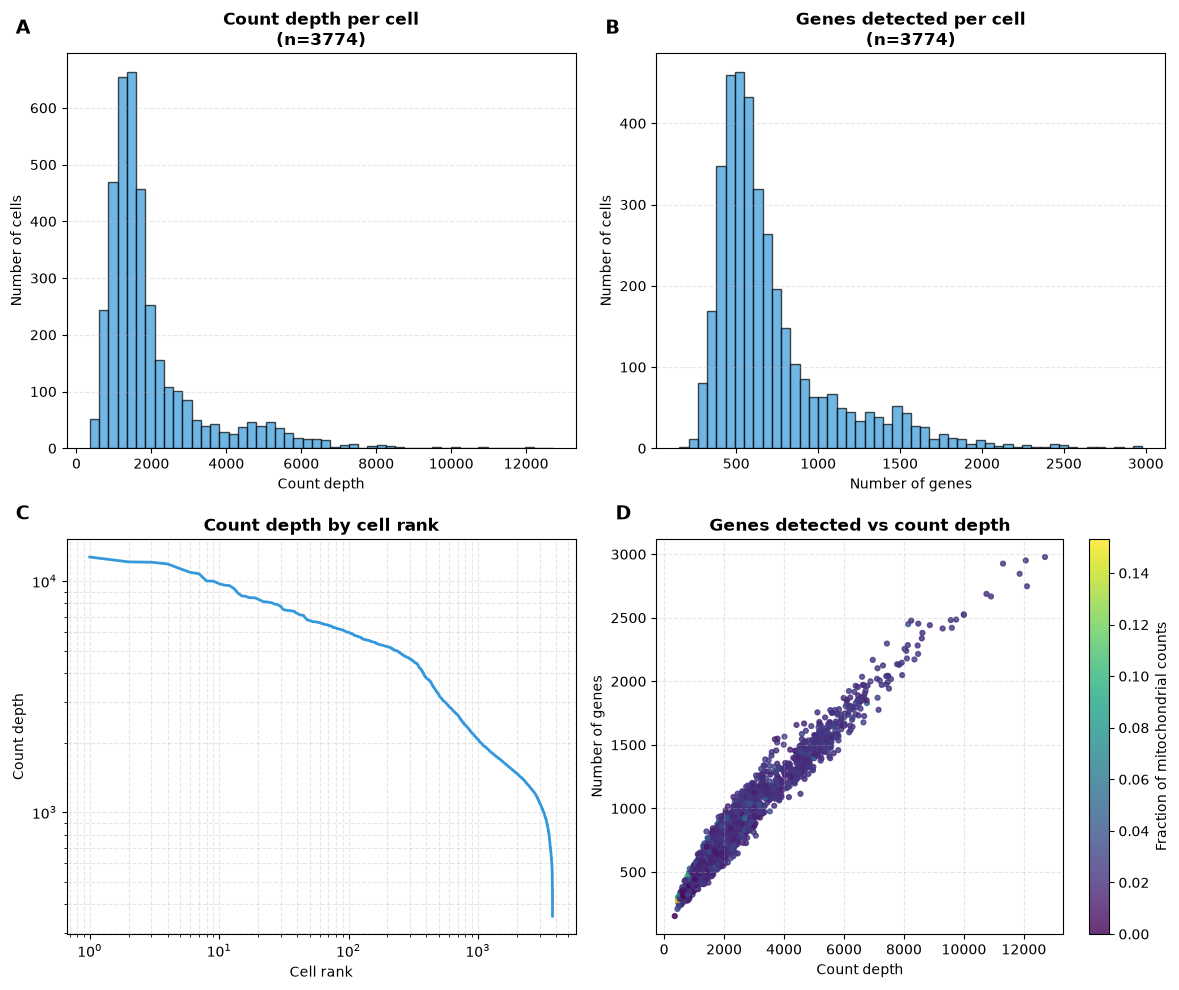

In [6]:
plot_qc_overview(
    raw_data,
    species=SPECIES,
    count_threshold=preprocessing_config.count_threshold,  # minimum count depth, set in the dataset config
    gene_threshold=preprocessing_config.gene_threshold,    # minimum genes per cell, set in the dataset config
)

## Mitochondrial, rRNA and apoptosis fractions

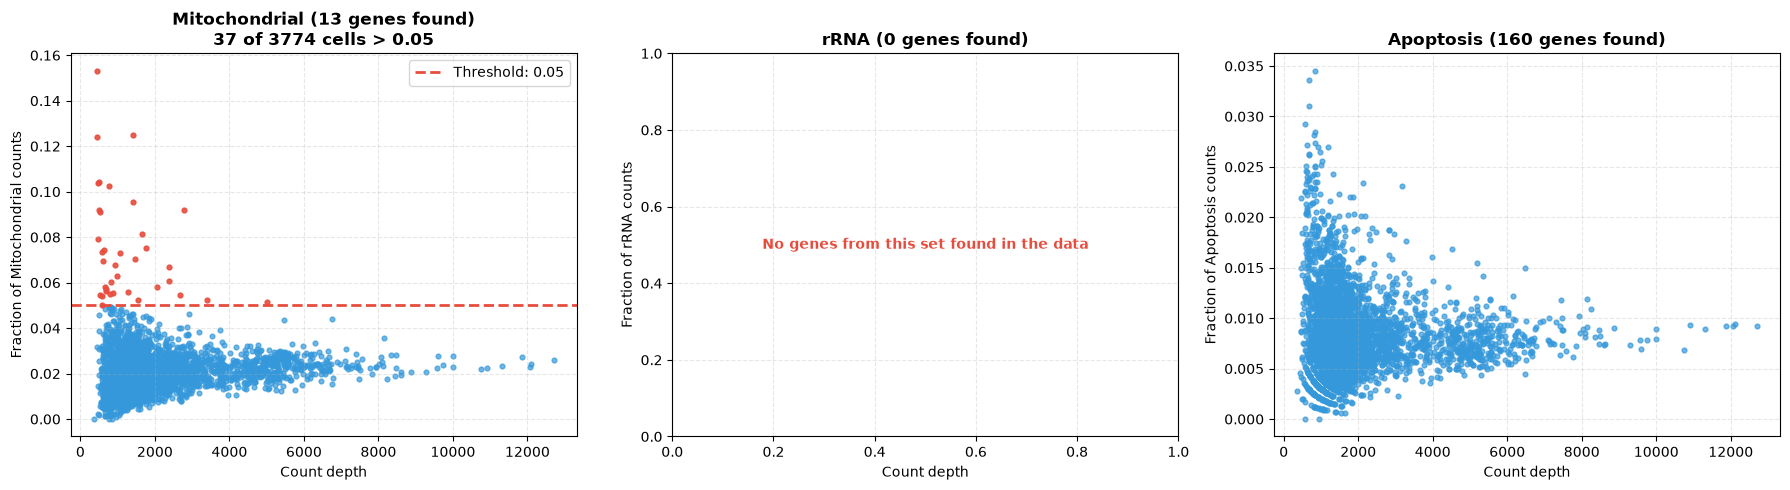

In [7]:
plot_gene_set_qc(raw_data, SPECIES, preprocessing_config)

## Genes

### Uniqueness

In [7]:
duplicates = duplicated_genes(raw_data)

print(f"Gene columns: {raw_data.shape[1]}, unique gene names: {raw_data.columns.nunique()}")
print(f"Gene names appearing in more than one column: {len(duplicates)}")
display(duplicates)

assert duplicates.empty, "Duplicated gene names found, see the table above"

Gene columns: 16791, unique gene names: 16791
Gene names appearing in more than one column: 0


,n_columns,identical_counts
gene,,


### Missing from the annotation

In [8]:
annotation = load_gene_annotation(SPECIES)
unmatched = unmatched_genes(raw_data, annotation)
alias_hits = unmatched.alias_matches
n_alias_genes = alias_hits["gene"].nunique()
n_ambiguous = alias_hits.loc[alias_hits["n_matches"] > 1, "gene"].nunique()

print(f"Genes matching no gene_id or gene_name: {n_alias_genes + len(unmatched.unknown_ensembl_ids) + len(unmatched.other)} / {raw_data.shape[1]}")
print(f"  found through alias_names: {n_alias_genes} ({n_ambiguous} matching more than one annotation row)")
print(f"  Ensembl IDs missing from the annotation: {len(unmatched.unknown_ensembl_ids)}, e.g. {unmatched.unknown_ensembl_ids[:5]}")
print(f"  other: {len(unmatched.other)}, e.g. {unmatched.other[:5]}")
display(alias_hits)

Genes matching no gene_id or gene_name: 684 / 16791
  found through alias_names: 0 (0 matching more than one annotation row)
  Ensembl IDs missing from the annotation: 684, e.g. ['ENSG00000237683', 'ENSG00000269554', 'ENSG00000203301', 'ENSG00000271895', 'ENSG00000242349']
  other: 0, e.g. []


,gene,n_matches,gene_id,gene_name,gene_biotype,chromosome,MT_status,RB_status,TF_status,APOPT_status,alias_names


### rRNA

In [9]:
# Same matching as filter_rrna_genes, so these are exactly the columns the pipeline drops
rrna_columns = matching_genes(raw_data, rrna_genes(SPECIES, annotation))
rrna_counts = raw_data[rrna_columns].sum().sort_values(ascending=False).rename("total_counts")

print(f"rRNA genes filtered out: {len(rrna_columns)} / {raw_data.shape[1]}")
print(f"  share of all counts: {rrna_counts.sum() / raw_data.values.sum():.3f}")
display(rrna_counts.to_frame())

rRNA genes filtered out: 0 / 16791
  share of all counts: 0.000


,total_counts


## Filtering pipeline

In [10]:
clean_data = run_filtering_pipeline(raw_data, config=preprocessing_config, species=SPECIES)

clean_data.shape

(3737, 9873)

### Low expression genes

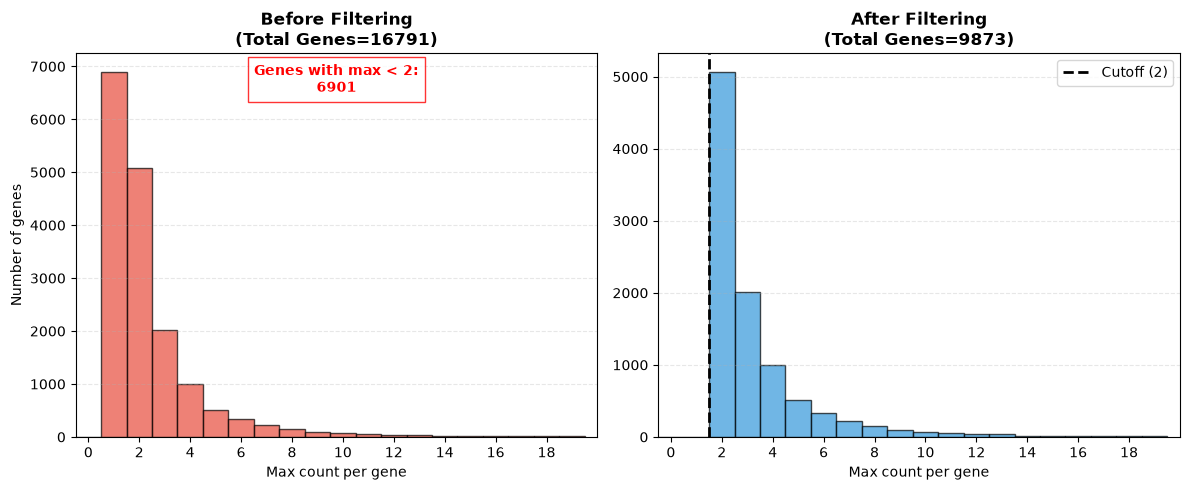

In [11]:
plot_gene_max_count_distribution(raw_data, clean_data, x_limit=20)

## Doublets (demonstration only)

We run the doublet filter to show how many cells it would remove, but the rest of the notebook continues from `clean_data`.

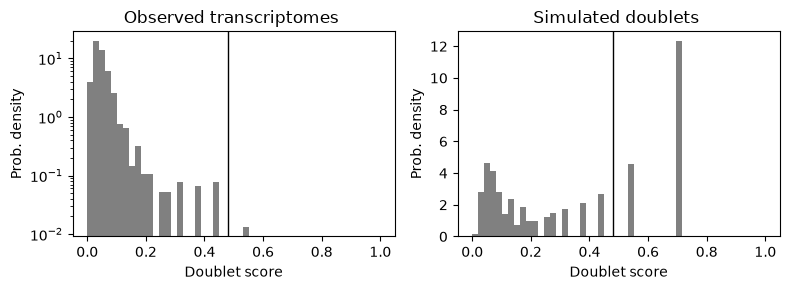

Cells removed as doublets: 1 / 3737


In [12]:
# For demonstration only: the rest of the notebook continues from clean_data, not from no_doublets_data
no_doublets_data = filter_doublets(clean_data)

print(f"Cells removed as doublets: {clean_data.shape[0] - no_doublets_data.shape[0]} / {clean_data.shape[0]}")

# Normalization

## logCPM

### Normalize by library size

In [13]:
normalized_data = normalize_by_library_size(clean_data)

normalized_data.shape

(3737, 9873)

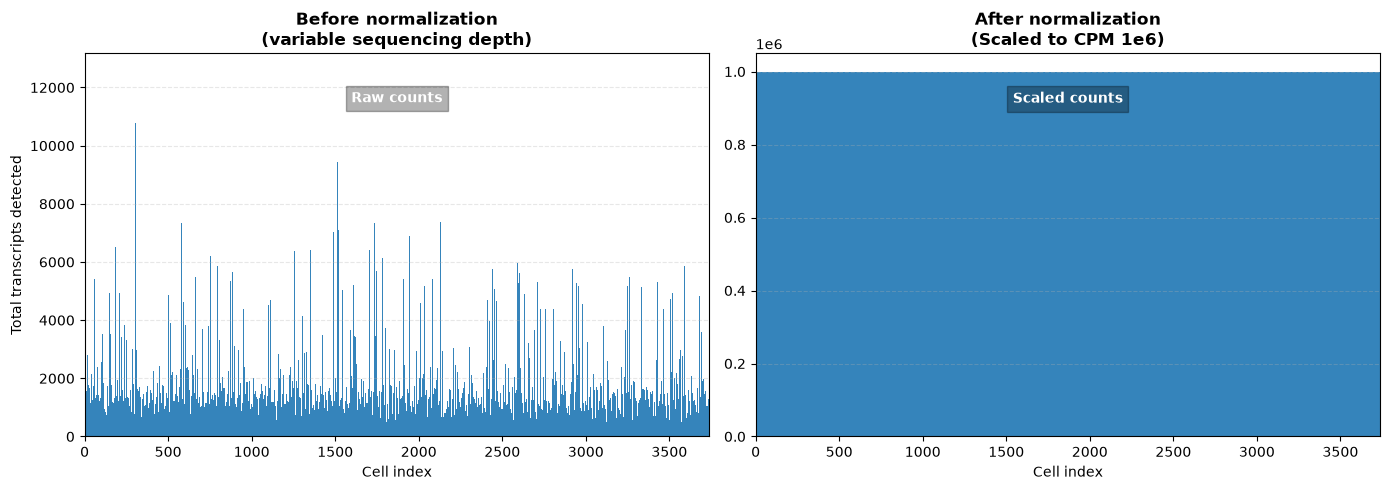

In [14]:
plot_normalization_comparison(clean_data, normalized_data, n_cells=normalized_data.shape[0])

### Log Transform

In [15]:
logged_data = log_transform(normalized_data)

logged_data.shape

(3737, 9873)

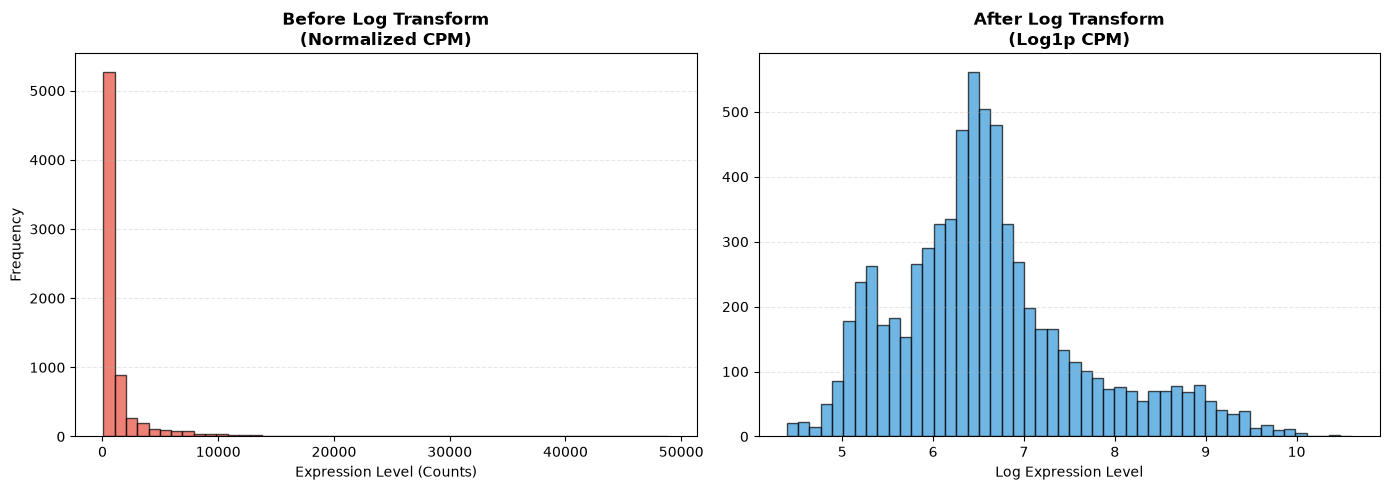

In [16]:
plot_log_transform_comparison(normalized_data, logged_data)

## Pearson residuals

In [17]:
pearsons_data = normalize_with_pearson(clean_data)

pearsons_data.shape

(3737, 9873)

In [18]:
pearsons_data.head()

,ENSG00000188976,ENSG00000188290,ENSG00000187608,ENSG00000186891,ENSG00000186827,ENSG00000078808,ENSG00000176022,ENSG00000260179,ENSG00000160087,ENSG00000131584,...,ENSG00000198899,ENSG00000198938,ENSG00000198840,ENSG00000212907,ENSG00000198886,ENSG00000198786,ENSG00000198695,ENSG00000198727,ENSG00000215700,ENSG00000215699
cell_id,,,,,,,,,,,,,,,,,,,,,
CGTGATGATTTCAC_1_b_cells,-0.237270,-0.059961,-0.481134,-0.248604,-0.223231,-0.374202,-0.142724,-0.021895,-0.291993,-0.140183,...,-0.718158,1.172036,-0.839068,-0.286198,0.399365,-1.052585,-0.153248,1.604364,-0.177174,-0.183810
TTTGACTGTTGAGC_1_cd34_filtered,-0.630644,-0.159627,1.048133,-0.660656,-0.593446,-0.992077,-0.379762,-0.058294,-0.775409,2.304157,...,2.849406,0.539807,3.035389,-0.760099,2.013272,2.410676,-0.407725,0.340736,-0.471268,-0.488883
GACAGTACCTGTGA_1_memory_t,-0.171270,-0.043277,-0.347445,-0.179453,-0.161134,-0.270166,-0.103014,-0.015802,-0.210785,-0.101180,...,-1.024117,-0.635147,-0.606610,-0.206600,-0.114853,-0.761713,8.928996,-1.394912,-0.127882,-0.132673
CAGACCCTATTCCT_1_b_cells,-0.194486,-0.049145,-0.394490,-0.203777,-0.182976,-0.306768,-0.116981,-0.017945,-0.239352,-0.114899,...,-0.311679,-1.000101,-0.688499,-0.234601,-1.650308,-0.864276,-0.125607,0.272185,6.739436,-0.150660
CAGCTAGATGACTG_1_cd4_t_helper,-0.187153,-0.047291,-0.379633,-0.196094,-0.176077,-0.295208,-0.112570,-0.017268,-0.230329,-0.110565,...,-1.117985,2.658107,-0.662647,-0.225757,-0.363334,1.555565,8.151237,-0.237335,-0.139744,6.751157
